# 05 · Quantização: o mesmo índice, uma fração da memória

O HNSW precisa dos vetores **em memória** para navegar no grafo. 1 bilhão de vetores × 1024 dims × 4 bytes = **4 TB de RAM**. Quantizar = guardar uma versão comprimida para navegar, e reavaliar (*rescore*) os melhores candidatos com o vetor original, que fica no disco.

| Método | Ideia | Bytes por vetor (1024 dims) |
|---|---|---|
| nenhum | float32 | 4.096 |
| **SQ** (scalar) | cada número vira 1 byte (precisa de treino) | ~1.024 |
| **RQ 8 bits** (rotational) | rotaciona e quantiza; sem treino, funciona com qualquer modelo | ~1.040 |
| **RQ 4 bits** (+ centering, v1.40) | idem com 4 bits; centering subtrai a média dos vetores | ~528 |
| **PQ** (product) | divide em segmentos e usa um codebook por segmento (k-means) | 256 com 256 segmentos |
| **BQ** (binary) | 1 bit por dimensão: só o sinal | 128 |

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import weaviate
from weaviate.classes.config import Configure, DataType, Property
import utils

vetores = utils.load_wiki_vectors(2)
vetores /= np.linalg.norm(vetores, axis=1, keepdims=True)
N_PERGUNTAS, K = 500, 10
dados, perguntas = vetores[:-N_PERGUNTAS], vetores[-N_PERGUNTAS:]
gabarito = np.argsort(-(perguntas @ dados.T), axis=1)[:, :K]

client = weaviate.connect_to_local()
Q = Configure.VectorIndex.Quantizer

/Users/dudanogueira/dev/weaviate/lab/claude/latinoware-2026/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def criar_e_carregar(nome, quantizador):
    client.collections.delete(nome)
    colecao = client.collections.create(
        nome,
        properties=[Property(name="linha", data_type=DataType.INT)],
        vector_config=Configure.Vectors.self_provided(vector_index_config=Configure.VectorIndex.hnsw(quantizer=quantizador)),
    )
    with colecao.batch.fixed_size(batch_size=1000) as batch:
        for linha, v in enumerate(dados):
            batch.add_object({"linha": linha}, vector=v)
    assert not colecao.batch.failed_objects
    # espera indexar e, se houver quantizador, comprimir
    utils.wait_for_indexing(client, nome, compressed=quantizador is not None)
    return colecao


def medir(colecao):
    acertos, inicio = 0.0, time.perf_counter()
    for q, certo in zip(perguntas, gabarito):
        r = colecao.query.near_vector(q, limit=K, return_properties=["linha"])
        acertos += utils.recall_at_k([o.properties["linha"] for o in r.objects], certo.tolist())
    return acertos / N_PERGUNTAS, (time.perf_counter() - inicio) / N_PERGUNTAS * 1000

## 1. A qualidade "crua" de cada compressão

Com `rescore_limit=0` o Weaviate **não** reavalia com o vetor original: vemos o erro da compressão sozinha.

In [3]:
crus = {
    "nenhum": None,
    "SQ": Q.sq(training_limit=10_000, rescore_limit=0),
    "RQ 8 bits": Q.rq(bits=8, rescore_limit=0),
    "RQ 4 bits": Q.rq(bits=4, rescore_limit=0),
    "RQ 4 bits + centering": Q.rq(bits=4, centering=True, rescore_limit=0),
    "BQ": Q.bq(rescore_limit=0),
}
resultado_cru = {}
for nome, quantizador in crus.items():
    resultado_cru[nome] = medir(criar_e_carregar("Quant" + "".join(c for c in nome if c.isalnum()), quantizador))
    print(f"{nome:22} recall@10={resultado_cru[nome][0]:.3f}")

nenhum                 recall@10=0.997


SQ                     recall@10=0.987


RQ 8 bits              recall@10=0.994


RQ 4 bits              recall@10=0.950


RQ 4 bits + centering  recall@10=0.959


BQ                     recall@10=0.994


## 2. Com rescore (o padrão)

Os candidatos finais são reavaliados com o vetor original, lido do disco. A memória continua a da versão comprimida.

In [4]:
padrao = {
    "SQ": Q.sq(training_limit=10_000),
    "RQ 8 bits": Q.rq(bits=8),
    "RQ 4 bits": Q.rq(bits=4),
    "RQ 4 bits + centering": Q.rq(bits=4, centering=True),
    "PQ": Q.pq(segments=256, training_limit=10_000),  # 1 byte por segmento de 4 dims
    "BQ": Q.bq(),
}
resultado = {"nenhum": resultado_cru["nenhum"]}
for nome, quantizador in padrao.items():
    resultado[nome] = medir(criar_e_carregar("QuantPadrao" + "".join(c for c in nome if c.isalnum()), quantizador))
    print(f"{nome:22} recall@10={resultado[nome][0]:.3f}  latência={resultado[nome][1]:.2f} ms")

SQ                     recall@10=0.997  latência=3.22 ms


RQ 8 bits              recall@10=0.998  latência=3.13 ms


RQ 4 bits              recall@10=0.999  latência=3.15 ms


RQ 4 bits + centering  recall@10=0.998  latência=3.12 ms


PQ                     recall@10=0.999  latência=4.32 ms


BQ                     recall@10=0.994  latência=3.25 ms


In [5]:
D = dados.shape[1]
pq_segmentos = 256
bytes_por_vetor = {"nenhum": D * 4, "SQ": D, "RQ 8 bits": D + 16, "RQ 4 bits": D // 2 + 16, "RQ 4 bits + centering": D // 2 + 16, "PQ": pq_segmentos, "BQ": D // 8}

tabela = pd.DataFrame({
    "bytes/vetor": bytes_por_vetor,
    "compressão": {k: D * 4 / v for k, v in bytes_por_vetor.items()},
    "recall cru": {k: v[0] for k, v in resultado_cru.items()},
    "recall com rescore": {k: v[0] for k, v in resultado.items()},
    "RAM p/ 100 mi vetores (GB)": {k: v * 100e6 / 1e9 for k, v in bytes_por_vetor.items()},
})
tabela.style.format({"bytes/vetor": "{:,.0f}", "compressão": "{:.0f}×", "recall cru": "{:.3f}", "recall com rescore": "{:.3f}", "RAM p/ 100 mi vetores (GB)": "{:,.0f}"}, na_rep="—")

,bytes/vetor,compressão,recall cru,recall com rescore,RAM p/ 100 mi vetores (GB)
nenhum,"4,096",1×,0.997,0.997,410
SQ,"1,024",4×,0.987,0.997,102
RQ 8 bits,"1,040",4×,0.994,0.998,104
RQ 4 bits,528,8×,0.950,0.999,53
RQ 4 bits + centering,528,8×,0.959,0.998,53
PQ,256,16×,—,0.999,26
BQ,128,32×,0.994,0.994,13


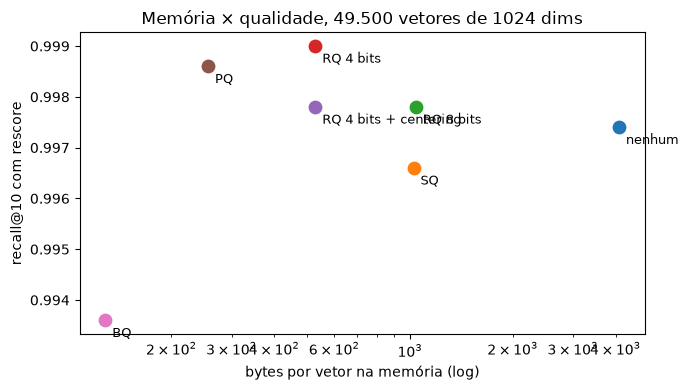

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for nome in bytes_por_vetor:
    x, y = bytes_por_vetor[nome], resultado[nome][0]
    ax.scatter(x, y, s=80)
    ax.annotate(nome, (x, y), xytext=(5, -12), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("bytes por vetor na memória (log)"); ax.set_ylabel("recall@10 com rescore")
ax.set_title("Memória × qualidade, 49.500 vetores de 1024 dims")
plt.tight_layout(); plt.show()

## O que levar para casa

- **RQ 8 bits** é a escolha segura: ~4× menos memória, sem treino e praticamente o mesmo recall. No open source, coleções nascem **sem** compressão; para mudar o padrão do cluster use `DEFAULT_QUANTIZATION=rq-8` (ou `rq-4`, `sq`, `pq`, `bq`, `rq-1`).
- Com rescore, até compressões agressivas ficam perto do recall original. O custo vira leitura de disco na busca: use SSD.
- BQ funciona bem com modelos grandes e "bem-comportados"; teste com **os seus** dados.
- ⚠️ `centering=True` só comprime com `ASYNC_INDEXING=true`: sem isso, o índice fica sem compressão e **sem aviso**.

➡️ `06_cluster_e_observabilidade.ipynb`

In [7]:
client.close()